# 02 — Algoritmo de rutas y validación de alternativas

**Práctica 4 · Logística del Valle** (puntos 3 y 4 del enunciado)

1. Comparamos algoritmos de búsqueda de rutas y justificamos la elección.
2. Implementamos **Dijkstra** (ruta de menor tiempo) y **Yen** (k mejores rutas) en `src/rutas.py` y verificamos que sean correctos.
3. Calculamos las rutas óptimas de **ida** y de **regreso** por separado.
4. Para cada destino comparamos la ruta actual contra al menos dos alternativas válidas y concluimos, con cálculos, si la ruta actual conviene.

In [1]:
import inspect
import itertools
import time

import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
from IPython.display import Markdown, display

from src import grafo as g
from src import rutas as r

pd.set_option("display.max_colwidth", None)
G = g.construir_grafo(g.cargar_matriz())
UMBRAL = 75

## 1. Selección del algoritmo (punto 3)

### Lo que exige esta red

| Característica | Consecuencia para el algoritmo |
|---|---|
| Grafo **dirigido** con 18 calles de un solo sentido y 14 tramos con tiempos distintos por sentido | Debe respetar el sentido de los arcos; ida y regreso se calculan por separado |
| Tiempos **positivos** (4 a 11 min) | No hacen falta algoritmos que admitan pesos negativos |
| **Sin coordenadas** | No hay una heurística geométrica natural |
| Red **pequeña** (40 nodos, 144 arcos) | La velocidad no es crítica; importan la **exactitud** y poder **recalcular** ante incidentes |
| El punto 4 pide **alternativas** | Además del óptimo se necesitan la 2.ª y 3.ª mejores rutas |

### Comparación

| Algoritmo | Complejidad | Ventajas | Limitaciones en esta red |
|---|---|---|---|
| **Dijkstra** | O((V+E) log V) | Exacto con pesos no negativos; respeta el sentido de los arcos; se recalcula al instante | Devuelve solo la ruta óptima |
| **A\*** | O((V+E) log V) en el peor caso | Explora menos nodos con una buena heurística | Sin coordenadas, la heurística hay que construirla; con `h = 0` es idéntico a Dijkstra |
| **Bellman-Ford** | O(V·E) | Admite pesos negativos | Más lento; su ventaja no aplica aquí |
| **Floyd-Warshall** | O(V³) | Todos los pares en una ejecución | Calcula 1 560 pares cuando solo usamos 8 |
| **Algoritmo genético** | Depende de parámetros | Sirve para ruteo con varias paradas (NP-difícil) | No garantiza el óptimo y es aleatorio; aquí existe una solución exacta y rápida |
| **Yen** | O(k·V·(V+E) log V) | Las k mejores rutas sin ciclos, ordenadas | Más costoso; es un complemento de Dijkstra |

**Elección:** **Dijkstra** para la ruta de menor tiempo y **Yen** (que usa Dijkstra internamente) para generar las alternativas.
No usamos heurística: con 40 nodos A\* no da una ganancia medible y Dijkstra garantiza el óptimo sin supuestos adicionales.
La justificación detallada está en el README.

## 2. Implementación

### Dijkstra

- La **cola de prioridad** (`heapq`) entrega siempre el nodo no visitado con menor tiempo acumulado; ese tiempo ya es definitivo.
- Solo recorre `G.succ[u]`, es decir, los **arcos que salen** de `u`. Por eso respeta el sentido de las calles.
- `arcos_excluidos` y `nodos_excluidos` permiten ignorar partes de la red sin copiarla (lo necesita Yen).
- Si el destino es inalcanzable (por ejemplo, tras cerrar tramos), devuelve `(None, inf)`.

In [2]:
display(Markdown(f"```python\n{inspect.getsource(r.dijkstra)}```"))

```python
def dijkstra(G, origen, destino, arcos_excluidos=frozenset(),
             nodos_excluidos=frozenset(), registro=None):
    """Ruta de menor tiempo de ``origen`` a ``destino`` en un grafo dirigido.

    Solo recorre arcos salientes, así que respeta el sentido de las calles.
    ``arcos_excluidos`` y ``nodos_excluidos`` permiten ignorar partes de la red
    sin copiarla (lo usa Yen). Si se pasa una lista en ``registro``, se agrega
    un paso por cada nodo extraído de la cola, para poder mostrar la traza.

    Devuelve (camino, minutos) o (None, inf) si el destino es inalcanzable.
    """
    distancia = {origen: 0.0}
    predecesor = {origen: None}
    visitados = set()
    cola = [(0.0, origen)]

    while cola:
        d, u = heapq.heappop(cola)
        if u in visitados:
            continue  # entrada vieja: ya se encontró una distancia menor
        visitados.add(u)

        actualizados = []
        if u != destino:
            for v, datos in G.succ[u].items():
                if v in visitados or v in nodos_excluidos or (u, v) in arcos_excluidos:
                    continue
                nueva = d + datos["peso"]
                if nueva < distancia.get(v, math.inf):
                    distancia[v] = nueva
                    predecesor[v] = u
                    heapq.heappush(cola, (nueva, v))
                    actualizados.append(f"{v}={nueva:g}")

        if registro is not None:
            registro.append({"paso": len(registro) + 1, "nodo fijado": u,
                             "distancia": d, "vecinos actualizados": ", ".join(actualizados)})
        if u == destino:
            break

    if destino not in visitados:
        return None, math.inf

    camino = [destino]
    while predecesor[camino[-1]] is not None:
        camino.append(predecesor[camino[-1]])
    return camino[::-1], distancia[destino]
```

### Yen

Parte de la ruta óptima y, para cada nodo de ella, fuerza un **desvío**: mantiene la *raíz* (el tramo inicial),
prohíbe los arcos que ya usaron las rutas encontradas con esa raíz y calcula con Dijkstra la mejor *espuela* hasta el destino.
Cada raíz + espuela es una candidata; la de menor tiempo es la siguiente ruta.

In [3]:
display(Markdown(f"```python\n{inspect.getsource(r.yen)}```"))

```python
def yen(G, origen, destino, k):
    """Las ``k`` rutas sin ciclos de menor tiempo, ordenadas (Yen, 1971).

    Devuelve una lista de (camino, minutos); puede tener menos de ``k``
    elementos si la red no admite más rutas distintas.
    """
    primero, costo = dijkstra(G, origen, destino)
    if primero is None:
        return []

    encontradas = [(primero, costo)]
    candidatas = []          # montículo de (minutos, camino)
    vistas = {tuple(primero)}

    while len(encontradas) < k:
        anterior = encontradas[-1][0]
        for i in range(len(anterior) - 1):
            desvio = anterior[i]
            raiz = anterior[:i + 1]

            # Arcos que ya usan las rutas encontradas con esta misma raíz.
            arcos = {(c[i], c[i + 1]) for c, _ in encontradas
                     if len(c) > i + 1 and c[:i + 1] == raiz}
            # Los nodos de la raíz (salvo el desvío) no pueden repetirse.
            nodos = set(raiz[:-1])

            espuela, _ = dijkstra(G, desvio, destino, arcos, nodos)
            if espuela is None:
                continue
            candidata = raiz[:-1] + espuela
            if tuple(candidata) not in vistas:
                vistas.add(tuple(candidata))
                heapq.heappush(candidatas, (costo_ruta(G, candidata), candidata))

        if not candidatas:
            break
        costo, camino = heapq.heappop(candidatas)
        encontradas.append((camino, costo))

    return encontradas
```

### Traza de Dijkstra: ida N01 → N19

Cada fila es un nodo que sale de la cola con su tiempo definitivo, y los vecinos cuyo tiempo mejoró.
El algoritmo se detiene al fijar el destino.

In [4]:
traza = []
camino, minutos = r.dijkstra(G, "N01", "N19", registro=traza)
print("Ruta:", " → ".join(camino), f"({minutos:g} min)")
pd.DataFrame(traza).set_index("paso")

Ruta: N01 → N02 → N18 → N19 (18 min)


,nodo fijado,distancia,vecinos actualizados
paso,,,
1,N01,0.0,"N02=8, N09=7, N17=9"
2,N09,7.0,N10=13
3,N02,8.0,"N03=16, N18=13"
4,N17,9.0,"N25=17, N26=19"
5,N10,13.0,N11=23
6,N18,13.0,N19=18
7,N03,16.0,"N04=25, N12=22"
8,N25,17.0,"N27=22, N33=25"
9,N19,18.0,


Solo hizo falta fijar unos pocos nodos para encontrar la ruta. Llega a N19 por **N02 → N18**, un tramo de **un solo sentido**:
la misma ruta no existe de regreso, y por eso el regreso se calcula por separado.

### Verificación

Comparamos nuestra implementación con la de `networkx`:

- **Dijkstra:** los 1 560 pares ordenados de nodos (40 × 39).
- **Yen:** las 6 mejores rutas de ida y de regreso de cada destino, contra `networkx.shortest_simple_paths`.

In [5]:
inicio = time.perf_counter()
diferencias = 0
for s, t in itertools.permutations(G.nodes, 2):
    camino, minutos = r.dijkstra(G, s, t)
    referencia = nx.dijkstra_path_length(G, s, t, weight="peso")
    if minutos != referencia or r.costo_ruta(G, camino) != minutos:
        diferencias += 1
duracion = time.perf_counter() - inicio
print(f"Dijkstra: {diferencias} diferencias en 1 560 pares ({duracion*1000:.0f} ms en total)")

filas = []
for s, t in [(g.BODEGA, d) for d in g.DESTINOS] + [(d, g.BODEGA) for d in g.DESTINOS]:
    propias = [m for _, m in r.yen(G, s, t, 6)]
    ref = [nx.path_weight(G, p, "peso")
           for p in itertools.islice(nx.shortest_simple_paths(G, s, t, weight="peso"), 6)]
    filas.append({"origen": s, "destino": t, "Yen propio": propias, "networkx": ref, "coinciden": propias == ref})
pd.DataFrame(filas)

Dijkstra: 0 diferencias en 1 560 pares (245 ms en total)


,origen,destino,Yen propio,networkx,coinciden
0,N01,N08,"[51.0, 52.0, 54.0, 55.0, 55.0, 55.0]","[51.0, 52.0, 54.0, 55.0, 55.0, 55.0]",True
1,N01,N19,"[18.0, 20.0, 24.0, 27.0, 28.0, 32.0]","[18.0, 20.0, 24.0, 27.0, 28.0, 32.0]",True
2,N01,N34,"[24.0, 24.0, 26.0, 27.0, 30.0, 31.0]","[24.0, 24.0, 26.0, 27.0, 30.0, 31.0]",True
3,N01,N40,"[47.0, 51.0, 54.0, 54.0, 54.0, 55.0]","[47.0, 51.0, 54.0, 54.0, 54.0, 55.0]",True
4,N08,N01,"[59.0, 59.0, 62.0, 63.0, 63.0, 63.0]","[59.0, 59.0, 62.0, 63.0, 63.0, 63.0]",True
5,N19,N01,"[24.0, 27.0, 32.0, 33.0, 39.0, 40.0]","[24.0, 27.0, 32.0, 33.0, 39.0, 40.0]",True
6,N34,N01,"[34.0, 42.0, 42.0, 43.0, 46.0, 47.0]","[34.0, 42.0, 42.0, 43.0, 46.0, 47.0]",True
7,N40,N01,"[61.0, 61.0, 62.0, 62.0, 63.0, 63.0]","[61.0, 61.0, 62.0, 62.0, 63.0, 63.0]",True


Ambas implementaciones coinciden en todos los casos. También se observan **empates**: hay destinos con dos rutas
distintas del mismo tiempo (por ejemplo, la ida a N34). Dijkstra devuelve una de ellas; Yen muestra las dos.

## 3. Rutas óptimas de ida y de regreso

In [6]:
optimas = r.rutas_optimas(G)
filas = []
for d, rr in optimas.items():
    (c_ida, t_ida), (c_reg, t_reg) = rr["ida"], rr["regreso"]
    filas.append({
        "destino": d,
        "ruta de ida": " → ".join(c_ida), "ida (min)": t_ida,
        "ruta de regreso": " → ".join(c_reg), "regreso (min)": t_reg,
        "ciclo (min)": t_ida + t_reg,
        "regreso = ida invertida": c_reg == c_ida[::-1],
    })
tabla_optimas = pd.DataFrame(filas).set_index("destino")
tabla_optimas

,ruta de ida,ida (min),ruta de regreso,regreso (min),ciclo (min),regreso = ida invertida
destino,,,,,,
N08,N01 → N09 → N10 → N11 → N13 → N22 → N23 → N07 → N08,51.0,N08 → N07 → N06 → N05 → N04 → N03 → N02 → N01,59.0,110.0,False
N19,N01 → N02 → N18 → N19,18.0,N19 → N18 → N10 → N09 → N01,24.0,42.0,False
N34,N01 → N17 → N26 → N34,24.0,N34 → N26 → N25 → N17 → N09 → N01,34.0,58.0,False
N40,N01 → N17 → N25 → N27 → N29 → N31 → N32 → N40,47.0,N40 → N32 → N31 → N29 → N27 → N11 → N10 → N09 → N01,61.0,108.0,False


En **ningún** destino la mejor ruta de regreso es la ida invertida, y el regreso siempre tarda más que la ida.
Esto se debe a que la salida **N01 → N17** y el tramo **N02 → N18** son de un solo sentido: sirven para salir, no para volver.

## 4. Validación de alternativas (punto 4)

Para cada destino comparamos cuatro opciones, con la ida y el regreso **calculados por separado**:

| Opción | Origen |
|---|---|
| **Actual** | Hojas de despacho (regreso = ida invertida) |
| **Dijkstra** | Ruta de menor tiempo (algoritmo implementado) |
| **Alternativa Yen 1 y 2** | Siguientes mejores rutas de Yen, distintas de la de Dijkstra y de la actual |

Todas las rutas son **válidas**: cada tramo existe en el sentido en que se recorre (lo comprobamos con `costo_ruta`).

In [7]:
def alternativas(origen, destino, actual, n=2):
    """Las n mejores rutas de Yen distintas de la de Dijkstra y de la actual."""
    optima = r.dijkstra(G, origen, destino)[0]
    salida = []
    for camino, minutos in r.yen(G, origen, destino, n + 3):
        if camino not in (optima, actual):
            salida.append((camino, minutos))
        if len(salida) == n:
            break
    return salida


opciones = {}   # destino -> {opción: {"ida": (camino, min), "regreso": (camino, min)}}
for d, actual in g.RUTAS_ACTUALES.items():
    alt_ida = alternativas(g.BODEGA, d, actual)
    alt_reg = alternativas(d, g.BODEGA, actual[::-1])
    opciones[d] = {
        "Actual": {"ida": (actual, r.costo_ruta(G, actual)),
                   "regreso": (actual[::-1], r.costo_ruta(G, actual[::-1]))},
        "Dijkstra": optimas[d],
        "Alternativa Yen 1": {"ida": alt_ida[0], "regreso": alt_reg[0]},
        "Alternativa Yen 2": {"ida": alt_ida[1], "regreso": alt_reg[1]},
    }

filas = []
for d, ops in opciones.items():
    t_actual = ops["Actual"]["ida"][1] + ops["Actual"]["regreso"][1]
    for nombre, rr in ops.items():
        (c_ida, t_ida), (c_reg, t_reg) = rr["ida"], rr["regreso"]
        assert r.costo_ruta(G, c_ida) == t_ida and r.costo_ruta(G, c_reg) == t_reg
        filas.append({
            "destino": d, "opción": nombre,
            "ida": " → ".join(c_ida), "ida (min)": t_ida,
            "regreso": " → ".join(c_reg), "regreso (min)": t_reg,
            "ciclo (min)": t_ida + t_reg,
            "ahorro vs actual (min)": t_actual - (t_ida + t_reg),
            "ahorro (%)": round(100 * (t_actual - (t_ida + t_reg)) / t_actual, 1),
            f"ida ≤ {UMBRAL}": t_ida <= UMBRAL,
            "margen de espera (min)": UMBRAL - t_ida,
        })
comparativa = pd.DataFrame(filas).set_index(["destino", "opción"])
comparativa

ida  \
destino opción                                                                                     
N08     Actual                                     N01 → N02 → N03 → N04 → N05 → N06 → N07 → N08   
        Dijkstra                             N01 → N09 → N10 → N11 → N13 → N22 → N23 → N07 → N08   
        Alternativa Yen 1                    N01 → N02 → N03 → N11 → N13 → N22 → N23 → N07 → N08   
        Alternativa Yen 2                    N01 → N09 → N10 → N11 → N13 → N22 → N23 → N16 → N08   
N19     Actual                                                       N01 → N02 → N03 → N11 → N19   
        Dijkstra                                                           N01 → N02 → N18 → N19   
        Alternativa Yen 1                                                  N01 → N17 → N18 → N19   
        Alternativa Yen 2                                            N01 → N09 → N10 → N18 → N19   
N34     Actual                                                 N01 → N09 → N17 → N25 → N33 → N34   
        Dijkstra                                                           N01 → N17 → N26 → N34   
        Alternativa Yen 1                                            N01 → N02 → N18 → N26 → N34   
        Alternativa Yen 2                                            N01 → N17 → N18 → N26 → N34   
N40     Actual             N01 → N02 → N03 → N04 → N05 → N06 → N07 → N08 → N16 → N24 → N32 → N40   
        Dijkstra                                   N01 → N17 → N25 → N27 → N29 → N31 → N32 → N40   
        Alternativa Yen 1                          N01 → N17 → N25 → N27 → N29 → N31 → N39 → N40   
        Alternativa Yen 2                    N01 → N09 → N17 → N25 → N27 → N29 → N31 → N32 → N40   

                           ida (min)  \
destino opción                         
N08     Actual                  59.0   
        Dijkstra                51.0   
        Alternativa Yen 1       52.0   
        Alternativa Yen 2       54.0   
N19     Actual                  33.0   
        Dijkstra                18.0   
        Alternativa Yen 1       20.0   
        Alternativa Yen 2       24.0   
N34     Actual                  42.0   
        Dijkstra                24.0   
        Alternativa Yen 1       24.0   
        Alternativa Yen 2       26.0   
N40     Actual                  93.0   
        Dijkstra                47.0   
        Alternativa Yen 1       51.0   
        Alternativa Yen 2       54.0   

                                                                                         regreso  \
destino opción                                                                                     
N08     Actual                                     N08 → N07 → N06 → N05 → N04 → N03 → N02 → N01   
        Dijkstra                                   N08 → N07 → N06 → N05 → N04 → N03 → N02 → N01   
        Alternativa Yen 1                          N08 → N07 → N06 → N05 → N12 → N03 → N02 → N01   
        Alternativa Yen 2              N08 → N07 → N23 → N22 → N29 → N27 → N11 → N10 → N09 → N01   
N19     Actual                                                       N19 → N11 → N03 → N02 → N01   
        Dijkstra                                                     N19 → N18 → N10 → N09 → N01   
        Alternativa Yen 1                                            N19 → N18 → N17 → N09 → N01   
        Alternativa Yen 2                                            N19 → N11 → N10 → N09 → N01   
N34     Actual                                                 N34 → N33 → N25 → N17 → N09 → N01   
        Dijkstra                                               N34 → N26 → N25 → N17 → N09 → N01   
        Alternativa Yen 1                                N34 → N26 → N33 → N25 → N17 → N09 → N01   
        Alternativa Yen 2                          N34 → N26 → N25 → N17 → N18 → N10 → N09 → N01   
N40     Actual             N40 → N32 → N24 → N16 → N08 → N07 → N06 → N05 → N04 → N03 → N02 → N01   
        Dijkstra                             N40 → N32 → N31 → N29 → N2

**Cómo leer la tabla**

- **ahorro vs actual:** minutos que se libera el vehículo en cada viaje redondo respecto a la ruta actual.
- **margen de espera:** cuánto puede esperar un pedido en cola y aun así entregarse a tiempo (75 − tiempo de ida).
  Si es negativo, la entrega nunca es puntual.

### Resumen numérico

In [8]:
resumen = comparativa[["ida (min)", "regreso (min)", "ciclo (min)"]].unstack("opción")
resumen = resumen.reorder_levels([1, 0], axis=1)[["Actual", "Dijkstra", "Alternativa Yen 1", "Alternativa Yen 2"]]
resumen

opción     Actual                            Dijkstra                \
        ida (min) regreso (min) ciclo (min) ida (min) regreso (min)   
destino                                                               
N08          59.0          59.0       118.0      51.0          59.0   
N19          33.0          33.0        66.0      18.0          24.0   
N34          42.0          42.0        84.0      24.0          34.0   
N40          93.0          93.0       186.0      47.0          61.0   

opción              Alternativa Yen 1                            \
        ciclo (min)         ida (min) regreso (min) ciclo (min)   
destino                                                           
N08           110.0              52.0          59.0       111.0   
N19            42.0              20.0          27.0        47.0   
N34            58.0              24.0          42.0        66.0   
N40           108.0              51.0          61.0       112.0   

opción  Alternativa Yen 2                            
                ida (min) regreso (min) ciclo (min)  
destino                                              
N08                  54.0          62.0       116.0  
N19                  24.0          32.0        56.0  
N34                  26.0          43.0        69.0  
N40                  54.0          62.0       116.0

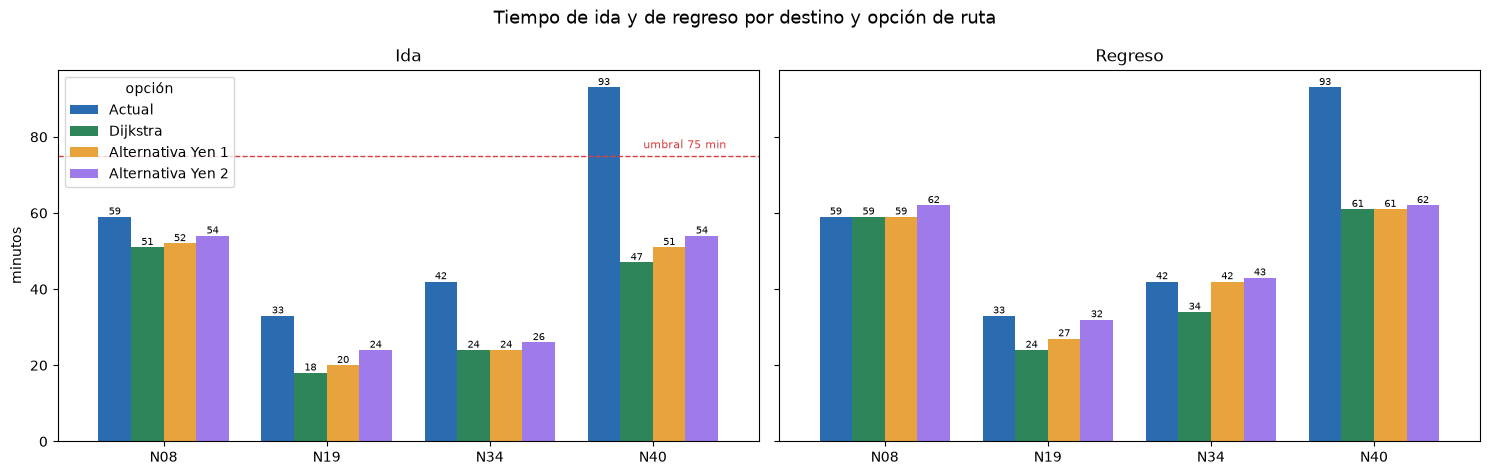

In [9]:
COLORES = {"Actual": "#2b6cb0", "Dijkstra": "#2f855a",
           "Alternativa Yen 1": "#e8a33d", "Alternativa Yen 2": "#9f7aea"}

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
for ax, tramo in zip(axes, ["ida (min)", "regreso (min)"]):
    datos = comparativa[tramo].unstack("opción")[list(COLORES)]
    datos.plot.bar(ax=ax, color=list(COLORES.values()), rot=0, width=0.8, legend=ax is axes[0])
    ax.set_title(tramo.replace(" (min)", "").capitalize())
    ax.set_ylabel("minutos")
    ax.set_xlabel("")
    for cont in ax.containers:
        ax.bar_label(cont, fmt="%g", fontsize=7)
axes[0].axhline(UMBRAL, color="#d93f3f", ls="--", lw=1)
axes[0].text(3.45, UMBRAL + 2, "umbral 75 min", color="#d93f3f", fontsize=8, ha="right")
fig.suptitle("Tiempo de ida y de regreso por destino y opción de ruta", fontsize=13)
plt.tight_layout()
plt.show()

### Rutas por destino

En cada figura: verde grueso = Dijkstra, naranja = Alternativa Yen 1, azul punteado = actual.

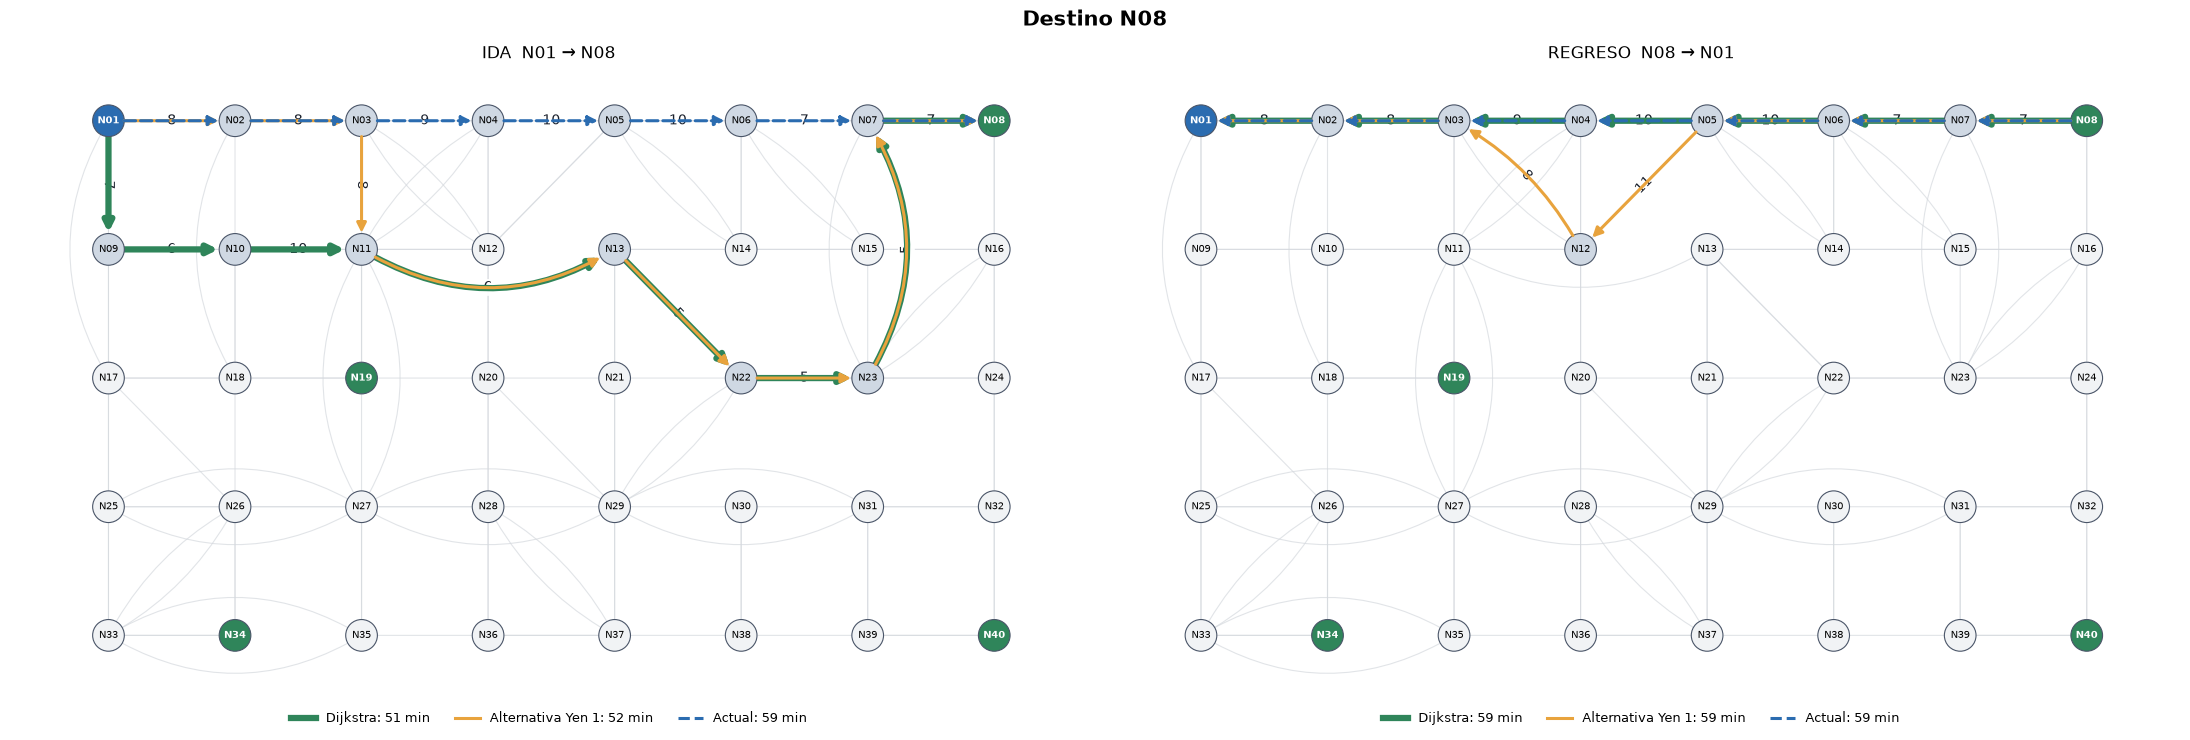

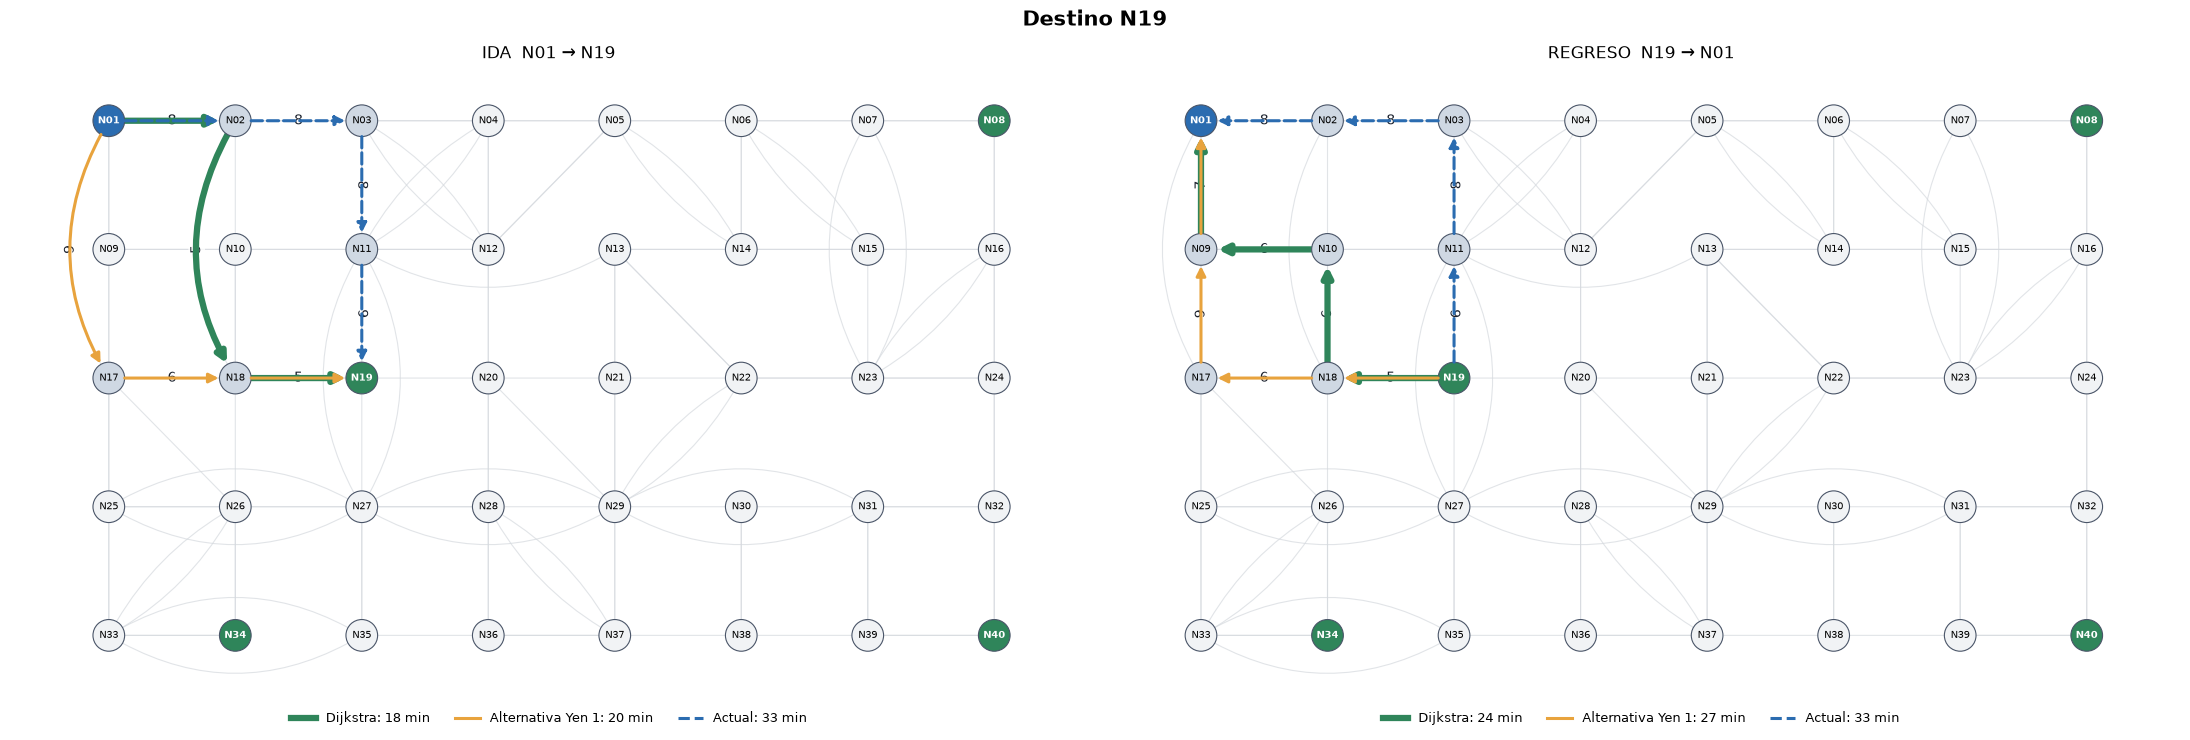

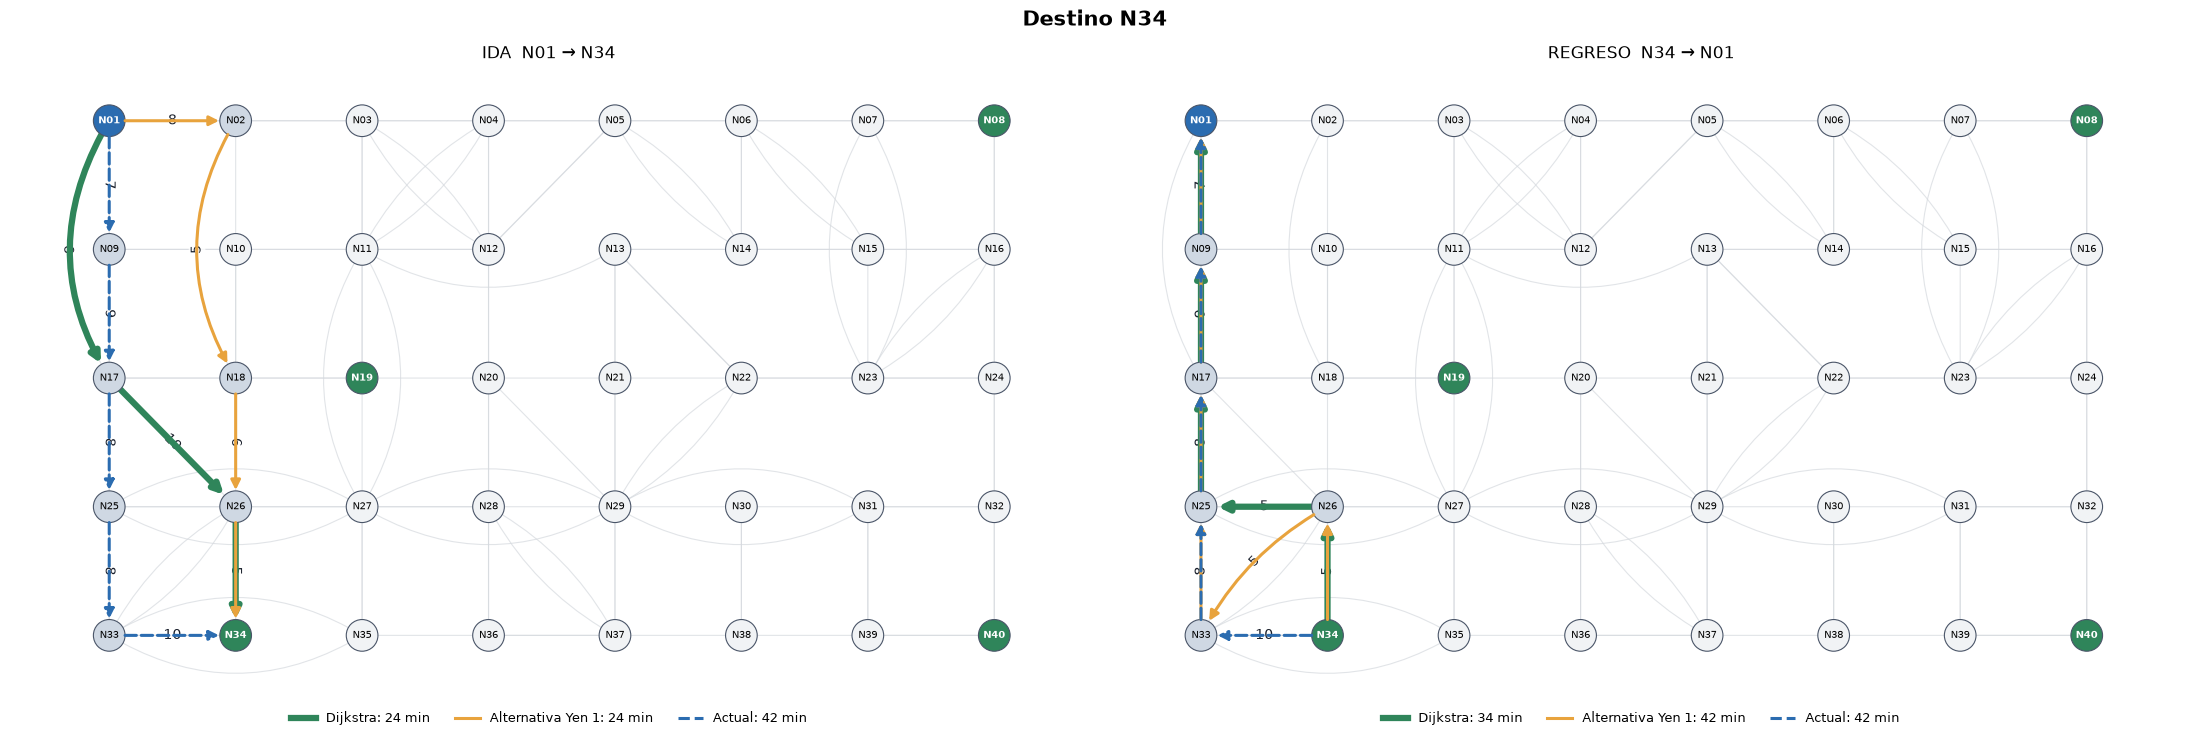

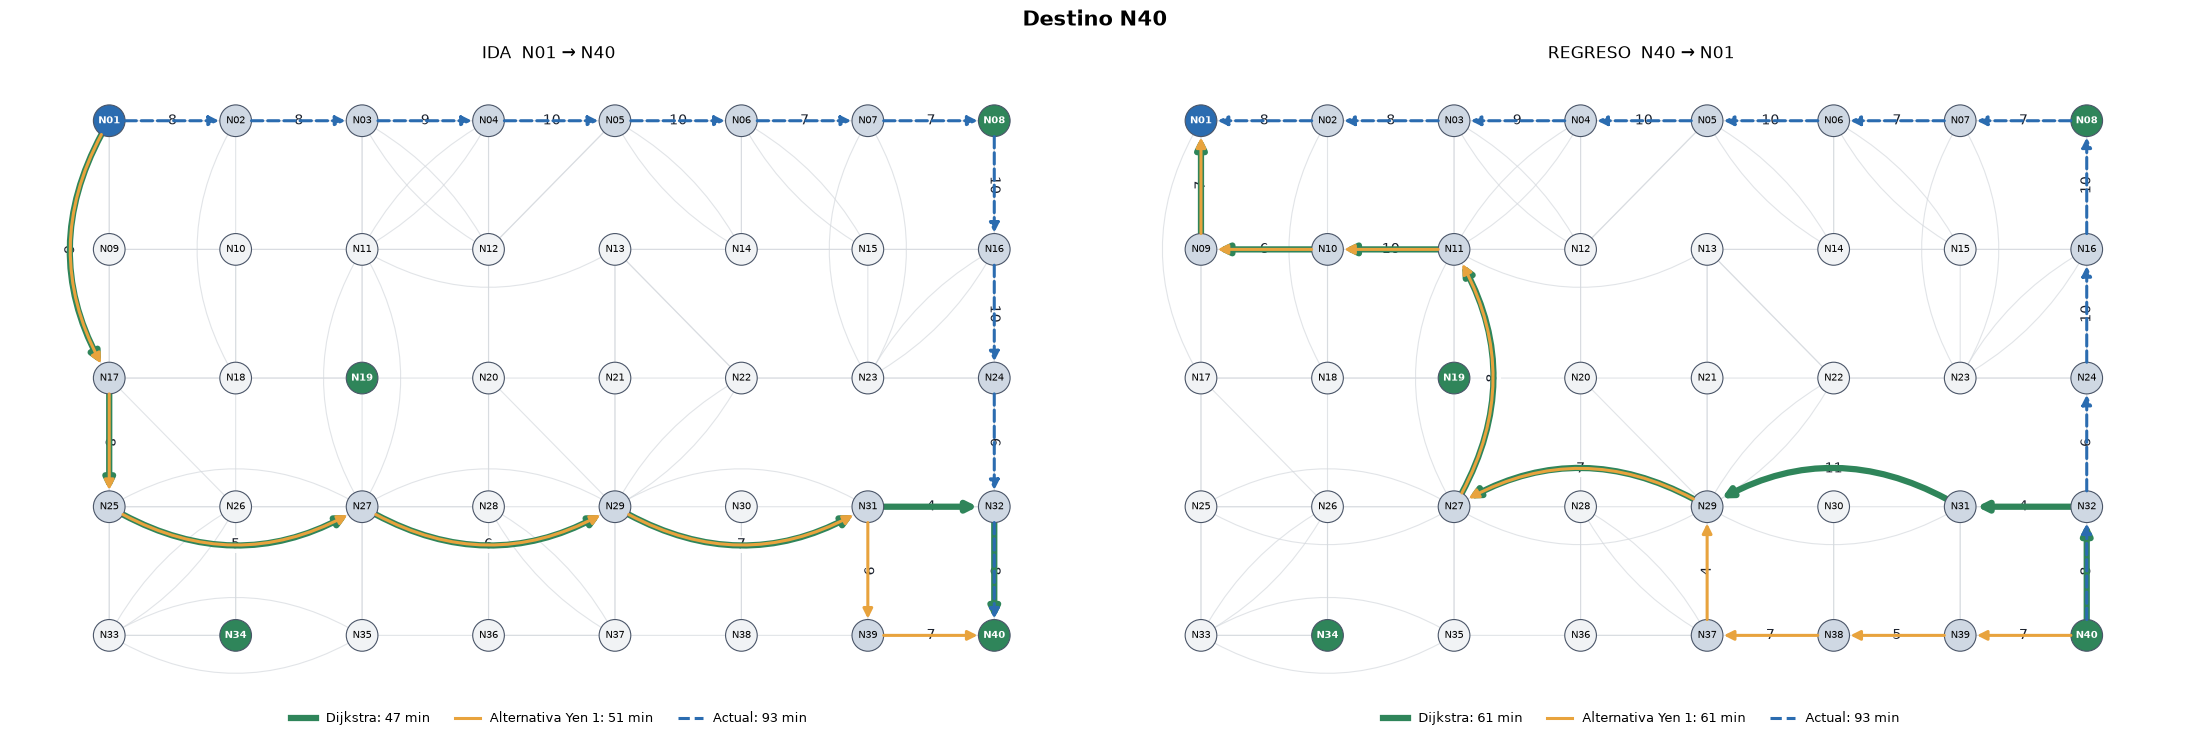

In [10]:
for d, ops in opciones.items():
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(22, 7.5))
    for ax, tramo, titulo in [(ax1, "ida", f"IDA  {g.BODEGA} → {d}"),
                              (ax2, "regreso", f"REGRESO  {d} → {g.BODEGA}")]:
        g.dibujar_rutas(G, [
            (ops["Dijkstra"][tramo][0], COLORES["Dijkstra"], f"Dijkstra: {ops['Dijkstra'][tramo][1]:g} min", "solid"),
            (ops["Alternativa Yen 1"][tramo][0], COLORES["Alternativa Yen 1"],
             f"Alternativa Yen 1: {ops['Alternativa Yen 1'][tramo][1]:g} min", "solid"),
            (ops["Actual"][tramo][0], COLORES["Actual"], f"Actual: {ops['Actual'][tramo][1]:g} min", "dashed"),
        ], ax=ax, titulo=titulo)
    fig.suptitle(f"Destino {d}", fontsize=15, fontweight="bold")
    plt.tight_layout()
    plt.show()

## 5. ¿Conviene la ruta actual?

Para cada destino calculamos la diferencia entre la ruta actual y la de Dijkstra, en la ida (afecta la **puntualidad**)
y en el ciclo completo (afecta la **disponibilidad del vehículo**).

In [11]:
lineas = []
for d, ops in opciones.items():
    a_ida, a_reg = ops["Actual"]["ida"][1], ops["Actual"]["regreso"][1]
    o_ida, o_reg = ops["Dijkstra"]["ida"][1], ops["Dijkstra"]["regreso"][1]
    y_ida, y_reg = ops["Alternativa Yen 1"]["ida"][1], ops["Alternativa Yen 1"]["regreso"][1]
    ciclo_a, ciclo_o = a_ida + a_reg, o_ida + o_reg
    lineas.append(
        f"**{d}.** Ida: actual {a_ida:g} min vs Dijkstra {o_ida:g} min "
        f"(−{a_ida - o_ida:g} min, −{100 * (a_ida - o_ida) / a_ida:.0f} %). "
        f"Regreso: {a_reg:g} vs {o_reg:g} min (−{a_reg - o_reg:g}). "
        f"Ciclo: {ciclo_a:g} → {ciclo_o:g} min (−{100 * (ciclo_a - ciclo_o) / ciclo_a:.0f} %). "
        f"Margen de espera para ser puntual: {UMBRAL - a_ida:g} → {UMBRAL - o_ida:g} min. "
        f"Incluso la Alternativa Yen 1 ({y_ida:g} + {y_reg:g} = {y_ida + y_reg:g} min) supera a la actual."
        if y_ida + y_reg < ciclo_a else
        f"**{d}.** Ida: actual {a_ida:g} min vs Dijkstra {o_ida:g} min. Regreso: {a_reg:g} vs {o_reg:g} min. "
        f"Ciclo: {ciclo_a:g} → {ciclo_o:g} min."
    )
display(Markdown("\n\n".join(lineas)))

tot_a = sum(o["Actual"]["ida"][1] + o["Actual"]["regreso"][1] for o in opciones.values()) / 4
tot_o = sum(o["Dijkstra"]["ida"][1] + o["Dijkstra"]["regreso"][1] for o in opciones.values()) / 4
display(Markdown(
    f"**Ciclo promedio** (los cuatro destinos son equiprobables): actual **{tot_a:g} min**, "
    f"Dijkstra **{tot_o:g} min** (−{100 * (tot_a - tot_o) / tot_a:.0f} %). "
    f"Capacidad teórica de 8 vehículos: {8 * 60 / tot_a:.1f} → **{8 * 60 / tot_o:.1f} pedidos por hora**."
))

**N08.** Ida: actual 59 min vs Dijkstra 51 min (−8 min, −14 %). Regreso: 59 vs 59 min (−0). Ciclo: 118 → 110 min (−7 %). Margen de espera para ser puntual: 16 → 24 min. Incluso la Alternativa Yen 1 (52 + 59 = 111 min) supera a la actual.

**N19.** Ida: actual 33 min vs Dijkstra 18 min (−15 min, −45 %). Regreso: 33 vs 24 min (−9). Ciclo: 66 → 42 min (−36 %). Margen de espera para ser puntual: 42 → 57 min. Incluso la Alternativa Yen 1 (20 + 27 = 47 min) supera a la actual.

**N34.** Ida: actual 42 min vs Dijkstra 24 min (−18 min, −43 %). Regreso: 42 vs 34 min (−8). Ciclo: 84 → 58 min (−31 %). Margen de espera para ser puntual: 33 → 51 min. Incluso la Alternativa Yen 1 (24 + 42 = 66 min) supera a la actual.

**N40.** Ida: actual 93 min vs Dijkstra 47 min (−46 min, −49 %). Regreso: 93 vs 61 min (−32). Ciclo: 186 → 108 min (−42 %). Margen de espera para ser puntual: -18 → 28 min. Incluso la Alternativa Yen 1 (51 + 61 = 112 min) supera a la actual.

**Ciclo promedio** (los cuatro destinos son equiprobables): actual **113.5 min**, Dijkstra **79.5 min** (−30 %). Capacidad teórica de 8 vehículos: 4.2 → **6.0 pedidos por hora**.

## 6. Actualización de rutas ante incidentes viales

Cuando cambia la red, basta con modificar el arco y **volver a ejecutar Dijkstra**: no hay rutas guardadas que invalidar.
`src.rutas.aplicar_incidente` devuelve una copia de la red con el tramo congestionado (nuevo tiempo) o cerrado (arco eliminado).

Probamos el peor cierre individual encontrado, **N09 → N01** (la entrada a la bodega por N09), y una congestión
del tramo **N02 → N18** de 5 a 20 minutos:

In [12]:
def cambios(H, nombre):
    nuevas = r.rutas_optimas(H)
    filas = []
    for d in g.DESTINOS:
        for tramo in ["ida", "regreso"]:
            antes, despues = optimas[d][tramo], nuevas[d][tramo]
            if antes[0] != despues[0]:
                filas.append({"incidente": nombre, "destino": d, "tramo": tramo,
                              "antes (min)": antes[1], "después (min)": despues[1],
                              "nueva ruta": " → ".join(despues[0])})
    return filas

incidentes = (cambios(r.aplicar_incidente(G, "N09", "N01"), "Cierre N09 → N01")
              + cambios(r.aplicar_incidente(G, "N02", "N18", 20), "Congestión N02 → N18 (20 min)"))
pd.DataFrame(incidentes).set_index(["incidente", "destino", "tramo"])

antes (min)  después (min)  \
incidente                     destino tramo                                 
Cierre N09 → N01              N19     regreso         24.0           33.0   
                              N34     regreso         34.0           47.0   
                              N40     regreso         61.0           62.0   
Congestión N02 → N18 (20 min) N19     ida             18.0           20.0   

                                                                                        nueva ruta  
incidente                     destino tramo                                                         
Cierre N09 → N01              N19     regreso                          N19 → N11 → N03 → N02 → N01  
                              N34     regreso        N34 → N26 → N25 → N27 → N11 → N03 → N02 → N01  
                              N40     regreso  N40 → N32 → N31 → N29 → N27 → N11 → N03 → N02 → N01  
Congestión N02 → N18 (20 min) N19     ida                                    N01 → N17 → N18 → N19

Solo cambian las rutas que usaban el tramo afectado; las demás se mantienen. La aplicación (fase 6) usará este
mismo mecanismo para que la gerente pruebe incidentes desde la interfaz.

## Conclusiones (puntos 3 y 4)

- **Dijkstra** es el algoritmo adecuado: la red es dirigida, con tiempos positivos y sin coordenadas. Es exacto y
  recalcula toda la red en milisegundos. **Yen** complementa con alternativas ordenadas. Ambas implementaciones propias
  coinciden con `networkx` en todos los casos probados.
- **Ninguna ruta actual es la más conveniente.** Dijkstra reduce el tiempo de ida en todos los destinos y el de regreso en
  tres de cuatro; en N08 el regreso actual ya es el de menor tiempo (59 min), pero su ida no.
- Las alternativas de Yen quedan muy cerca del óptimo (en la ida a N34 hay un **empate** de 24 min) y, en el ciclo completo,
  también superan a la ruta actual en los cuatro destinos. Es decir, la ruta actual no solo no es la mejor: está por detrás
  de varias opciones válidas.
- La mayor ganancia está en **N40**: la ida pasa de 93 a 47 min, lo que convierte un destino **imposible de atender a tiempo**
  en uno con 28 minutos de margen de espera.
- **La ida y el regreso óptimos nunca coinciden**, por las calles de un solo sentido y los tramos asimétricos. Las hojas de
  despacho, que suponen regresar por el mismo camino, desaprovechan esos atajos.
- El ciclo promedio por pedido baja alrededor de un 30 %, lo que aumenta la capacidad teórica de la flota de ~4.2 a ~6 pedidos
  por hora. La simulación (fase 5) medirá el efecto real con llegadas aleatorias y cola.